# NATS: TAG appraisal of additional charging capacity

**Separate analysis of saved simulator results.** No aircraft simulation is embedded or run in this notebook.

The comparison adds one charger at each of four vertiports, holding the 14-aircraft fleet, four seats, five stands per port, routes and timetable constant. It uses 80 matched simulation seeds from the existing `nats_capacity_study_v2_1` experiment. Additional passenger/energy exports reproduce its original 12-hour summaries.

The question is: **how much value is attributable to the observed time savings, what additional energy do they require, and what budget might remain for other costs?**

Results are a **partial TAG-informed appraisal**. Unfinished journeys remain in the data; their unobserved later outcomes are not known. No full welfare benefit, operator profit, benefit-cost ratio or procurement recommendation is claimed.

## 1. Files and adjustable appraisal assumptions

`appraisal.py` reads the saved results and implements the arithmetic. `reporting.py` produces tables and figures from those calculations. The optional exporter runs separately in the original simulator environment and is not imported here.

The example 300 operating days/year, 10-year duration and 2027 opening are **declared scenarios**, not sourced operating forecasts or equipment lives. Alternative annual use and durations are evaluated below. Different physical networks must first be simulated in the original project and exported; changing an economic assumption here does not alter the physical simulation.

In [1]:
from dataclasses import replace
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'appraisal.py').exists():
    raise RuntimeError('Open this notebook from the nats_tag_appraisal_v1 folder.')
sys.path.insert(0, str(ROOT))
from appraisal import (AppraisalCase, load_inputs, load_pairs, mean_ci,
    daily_components, benefit_budget, upfront_budget, net_present_value,
    residual_time_adjustment, time_value, energy_value)
from reporting import analyse, export_tables, figures

CASE = AppraisalCase(
    purpose='other_non_work',
    waiting_multiplier=2.0,
    energy_scenario='central',
    operating_days=300,
    opening_year=2027,
    years=10,
)
report, pairs, evidence = analyse(CASE)
print(f"Loaded {len(pairs)} matched pairs ({2*len(pairs)} saved simulation runs).")
print('No aircraft simulator has been imported or run.')
print('Monetary units: real 2023 GBP; discounted totals use a 2023 PV base.')

Loaded 80 matched pairs (160 saved simulation runs).
No aircraft simulator has been imported or run.
Monetary units: real 2023 GBP; discounted totals use a 2023 PV base.


## 2. Published inputs and their applicability

TAG A5.2, section 3.2.8, allows surface-mode values for leisure/commuting aviation appraisal when aviation-specific values are absent. Business values need separate justification; no business default or invented passenger mix is used.

The waiting multiplier of 2 is a **public-transport transfer proxy**, from TAG A1.3 section 4.4.1. Only pre-boarding waiting receives that multiplier. All later observed ground/onboard time receives a unit multiplier as an explicit simplification. A multiplier of 1 is tested separately.

Energy is valued using DESNZ's long-run variable supply cost, not the operator's retail bill. The source's 2025 price base is converted to 2023, and factor-cost units are converted to market-price units using 1.19. The time values are already in market-price units and are not converted again.

In [2]:
input_rows = [
    ['Other non-work time', time_value(evidence, replace(CASE, purpose='other_non_work'), 2026),
     'GBP/person-hour; 2023 prices, 2026 value', 'S01 A1.3.1 F48; Annual Parameters AA81/AA78'],
    ['Commuting time', time_value(evidence, replace(CASE, purpose='commuting'), 2026),
     'GBP/person-hour; 2023 prices, 2026 value', 'S01 A1.3.1 F47; Annual Parameters AA81/AA78'],
    ['Waiting multiplier', CASE.waiting_multiplier, 'dimensionless; transfer proxy', 'S02 section 4.4.1'],
    ['Electricity resource cost', energy_value(evidence, CASE, 2026),
     'GBP/kWh; 2023 prices, market-price units', 'S15 Table 9 F24; S01 D78/D80 and indirect tax factor'],
    ['Initial real discount rate', CASE.discount_rates[0], 'fraction/year', 'S13 HMT October 2026'],
]
display(pd.DataFrame(input_rows, columns=['Input', 'Value', 'Units / scope', 'Source']).round(4))
sources = json.loads((ROOT / 'data/source_register.json').read_text())
for sid in ['S01','S02','S04','S14','S15','S13']:
    s = next(x for x in sources if x['id'] == sid)
    display(Markdown(f"**{sid}:** [{s['title']}]({s['url']}) — {s['exact_location']}"))

,Input,Value,Units / scope,Source
0,Other non-work time,7.2073,"GBP/person-hour; 2023 prices, 2026 value",S01 A1.3.1 F48; Annual Parameters AA81/AA78
1,Commuting time,15.7905,"GBP/person-hour; 2023 prices, 2026 value",S01 A1.3.1 F47; Annual Parameters AA81/AA78
2,Waiting multiplier,2.0000,dimensionless; transfer proxy,S02 section 4.4.1
3,Electricity resource cost,0.1541,"GBP/kWh; 2023 prices, market-price units",S15 Table 9 F24; S01 D78/D80 and indirect tax ...
4,Initial real discount rate,0.0300,fraction/year,S13 HMT October 2026


**S01:** [DfT TAG Data Book v2.03](https://assets.publishing.service.gov.uk/media/6a576e102f6185941a9a6569/tag-data-book-v2-03.xlsm) — A1.3.1 F47/F48; Annual Parameters D78/D80, AA78/AA81; A1.1.1 D25:D27

**S02:** [DfT TAG A1.3 User and Provider Impacts](https://assets.publishing.service.gov.uk/media/6a034015e71c4cdf4026baae/tag-unit-a1-3-user-and-provider-impacts.pdf) — Sections 4.3-4.5, pp.15-16

**S04:** [DfT TAG A5.2 Aviation Appraisal](https://assets.publishing.service.gov.uk/media/6899e2b43080e72710b2e34f/tag-unit-a5-2-aviation-appraisal.pdf) — Sections 3.2.8-3.2.11, p.7

**S14:** [DESNZ Valuation of energy use and greenhouse gas emissions for appraisal](https://assets.publishing.service.gov.uk/media/6ae370c5d22fc5fecb3eb800/valuation-of-energy-use-and-greenhouse-gas-emissions-for-appraisal.pdf) — Sections 3.3-3.7, pp.10-11

**S15:** [DESNZ energy and emissions appraisal data October 2026](https://assets.publishing.service.gov.uk/media/6ae35a4b83b993d8d93eb791/data_tables_1-18-oct-2026.xlsx) — Table 9 B5, C24/F24/I24; Notes B7

**S13:** [HM Treasury response to discount rate review October 2026](https://www.gov.uk/government/publications/green-book-discount-rate-review-2026/green-book-discount-rate-review-hm-treasury-response) — Introduction, Box 1.A

## 3. Physical outputs, including unfinished journeys

All offered passengers contribute to observed time. For a passenger not boarded by the common horizon $T$, waiting is measured until $T$. For a passenger not yet completed, post-boarding time is measured only until $T$. Future time is unknown and is kept separate.

For run $i$, let $W_i(T)$ be total observed pre-boarding passenger-minutes and $O_i(T)$ observed passenger-minutes after boarding. A and B denote one and two chargers per port.

Energy accounting is
$$E_i^{\rm equiv}=E_i^{\rm grid}+\frac{E_i^{\rm initial}-E_i^{\rm terminal}}{\eta}.$$
This charges each option for restoring its terminal battery deficit. It does not simulate overnight charging capacity, fleet repositioning, degradation or thermal losses. Those limitations remain part of the interpretation.

,metric,option,mean,low,high
0,Waiting before boarding (passenger-hours/day),One charger per port,110.087,106.723,113.510
1,Waiting before boarding (passenger-hours/day),Two chargers per port,78.945,77.011,80.896
2,Time after boarding (passenger-hours/day),One charger per port,109.883,108.204,111.490
3,Time after boarding (passenger-hours/day),Two chargers per port,107.303,105.752,108.823
4,Grid energy including battery restoration (kWh...,One charger per port,4030.097,3998.634,4061.976
5,Grid energy including battery restoration (kWh...,Two chargers per port,4574.436,4532.313,4614.917
6,Flights/day,One charger per port,200.950,199.375,202.538
7,Flights/day,Two chargers per port,227.912,225.812,229.925
8,Unfinished passengers/day,One charger per port,0.762,0.425,1.138
9,Unfinished passengers/day,Two chargers per port,0.962,0.675,1.288


,Metric,mean,low,high
0,Waiting hours saved/day,31.142,28.115,34.305
1,Additional kWh/day,544.339,501.598,586.774
2,Additional unfinished passengers/day,0.200,-0.212,0.600
3,Change in chance of an unfinished day (fraction),0.238,0.100,0.375


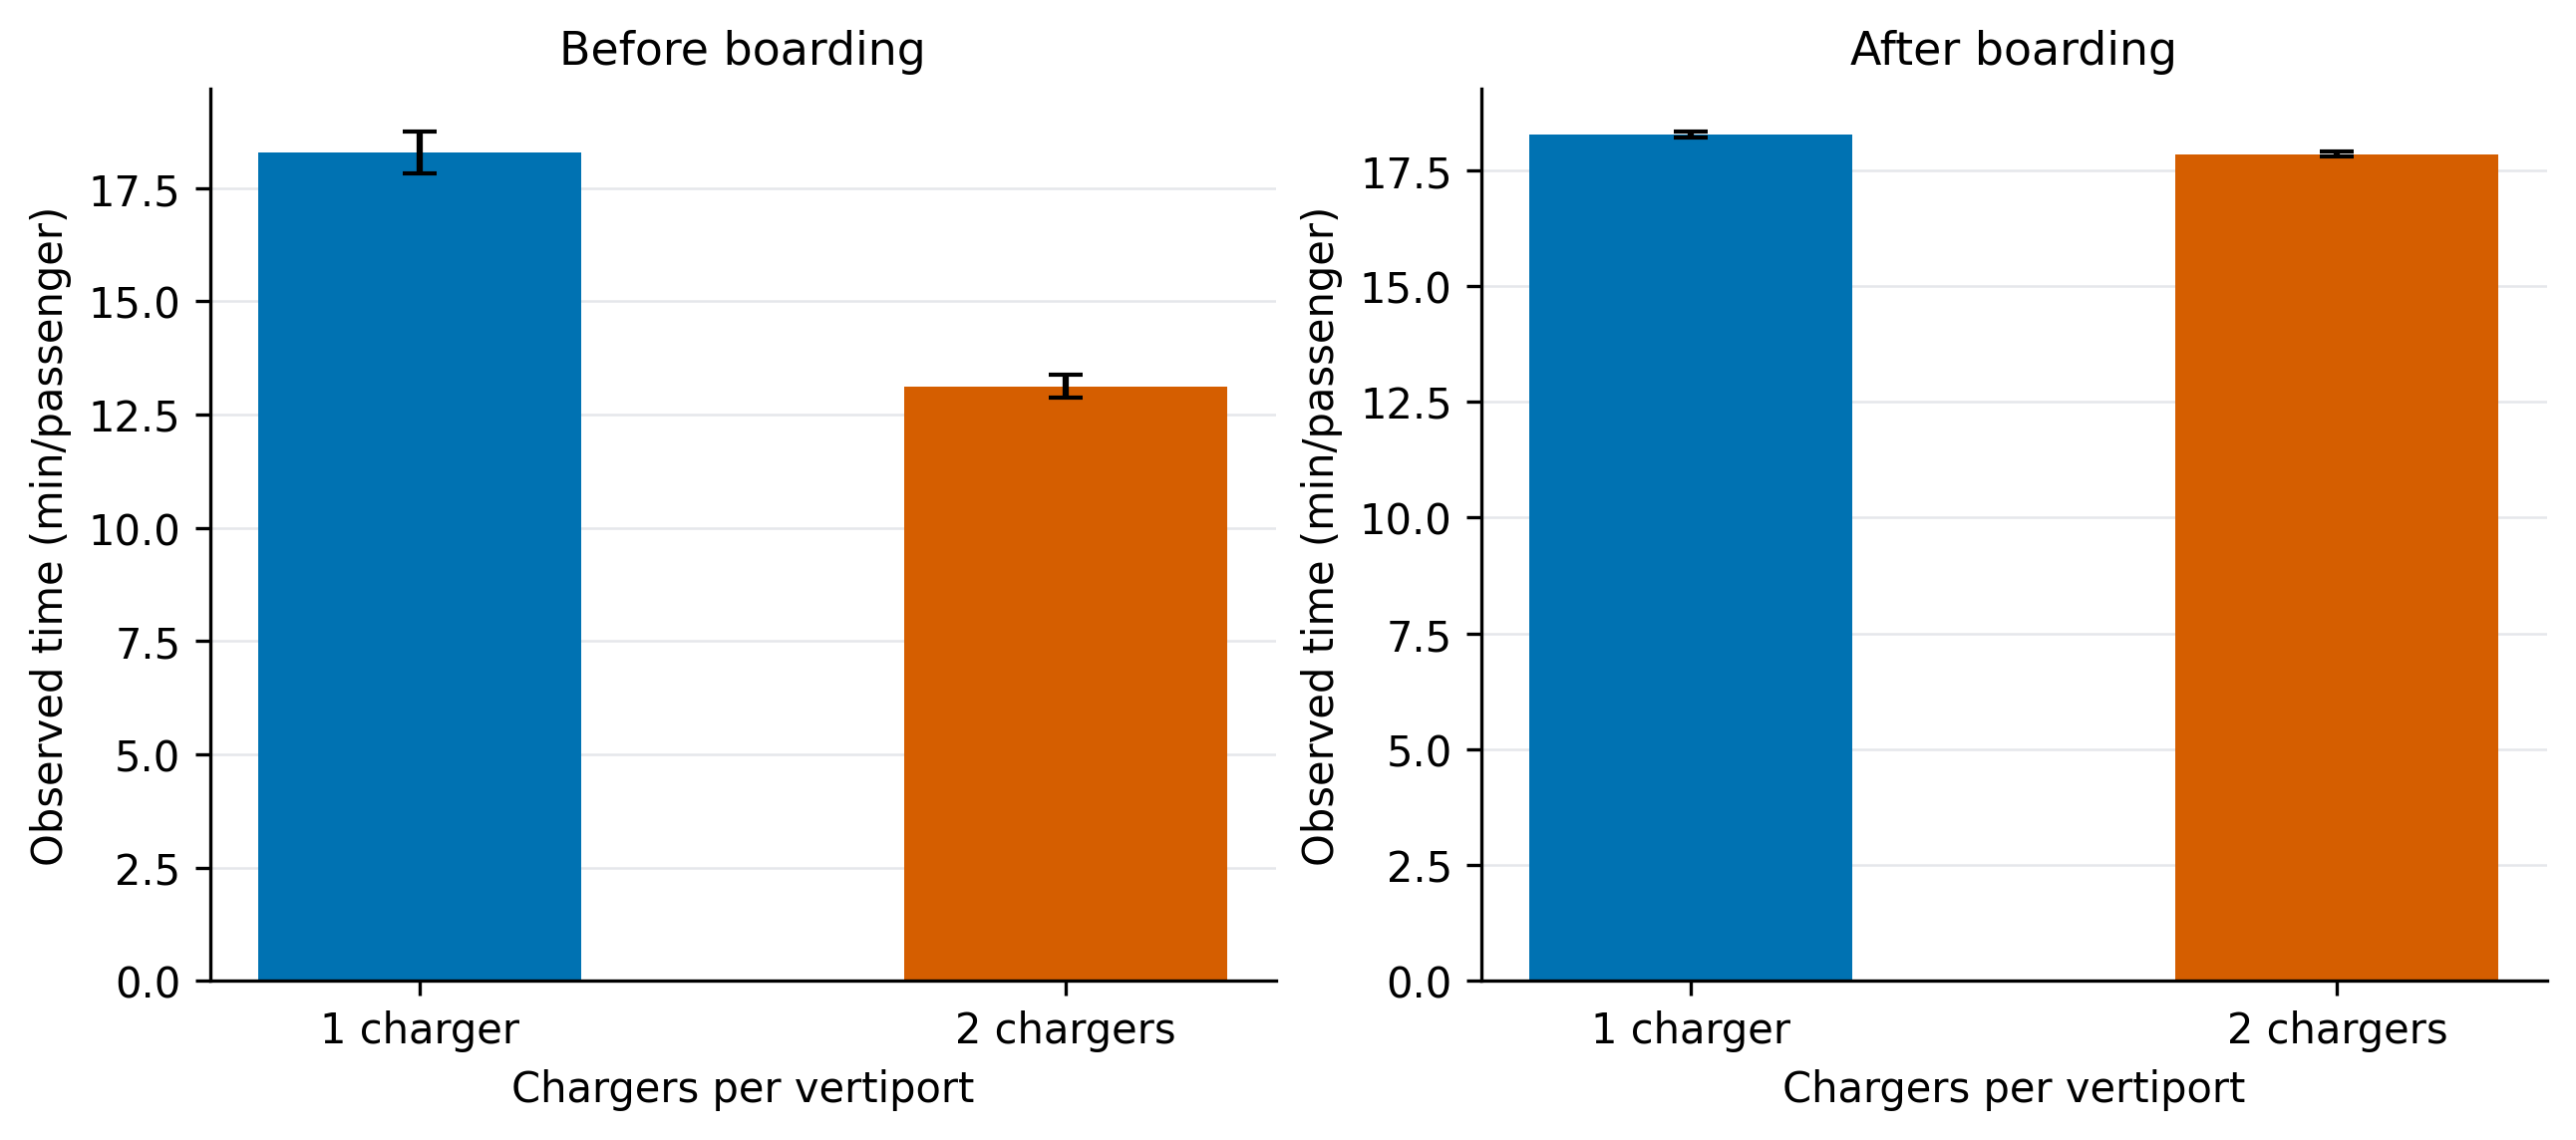

Mean observed time per offered passenger over 12 hours, across 80 paired replications. All passengers are retained, including unfinished journeys. Before-boarding time is separated from later ground/onboard time. Bars show run-mean averages; error bars are 95% whole-run percentile bootstrap confidence intervals (5,000 resamples). This is a finite-horizon time burden, not eventual whole-journey time.

In [3]:
physical = pd.DataFrame(report['physical'])
display(physical[['metric','option','mean','low','high']].round(3))
display(pd.DataFrame([
    {'Metric': 'Waiting hours saved/day', **report['wait_hours_saved']},
    {'Metric': 'Additional kWh/day', **report['extra_energy']},
    {'Metric': 'Additional unfinished passengers/day', **report['extra_unfinished']},
    {'Metric': 'Change in chance of an unfinished day (fraction)', **report['extra_unfinished_day']},
])[['Metric','mean','low','high']].round(3))

captions = figures(report, pairs, evidence)
export_tables(report, pairs)
display(Image(filename=str(ROOT/'figures/01_passenger_time.png'), width=900))
display(Markdown(captions['01_passenger_time']))

## 4. Monetary calculation and paired bootstrap

The observed daily time-and-energy component is
$$b_{i,y}^{\rm partial}=\frac{v_y}{60}\{m[W_{i,A}(T)-W_{i,B}(T)]+O_{i,A}(T)-O_{i,B}(T)\}
-p_y[E_{i,B}^{\rm equiv}-E_{i,A}^{\rm equiv}].$$

$v_y$ is the purpose-specific value of time, $m$ the waiting multiplier and $p_y$ the consistent energy resource value. The code stores hours, so the minute-to-hour conversion occurs during data loading.

This is an **observed component**, not complete consumer surplus: unserved demand and later journey outcomes remain unresolved. The rule-of-half is not applied to a synthetic fixed-demand experiment without a calibrated demand response. The original operational-score weights are not used as money prices.

Each seed supplies one paired difference. The bootstrap resamples the 80 pairs **with replacement**, 5,000 times, and takes the 2.5th and 97.5th percentiles of their means. These are conditional confidence intervals for the mean, not 95% ranges for individual days. No stationarity assumption or independent-passenger assumption is needed for independent finite-day replications. The 5,000 resamples are not 5,000 new aircraft simulations.

,purpose,component,mean,low,high
0,other_non_work,time_benefit,467.49,423.29,514.52
1,other_non_work,extra_energy_cost,83.90,77.31,90.44
2,other_non_work,partial_net_benefit,383.59,343.44,425.13
3,commuting,time_benefit,1024.23,927.39,1127.28
4,commuting,extra_energy_cost,83.90,77.31,90.44
5,commuting,partial_net_benefit,940.33,847.10,1037.76


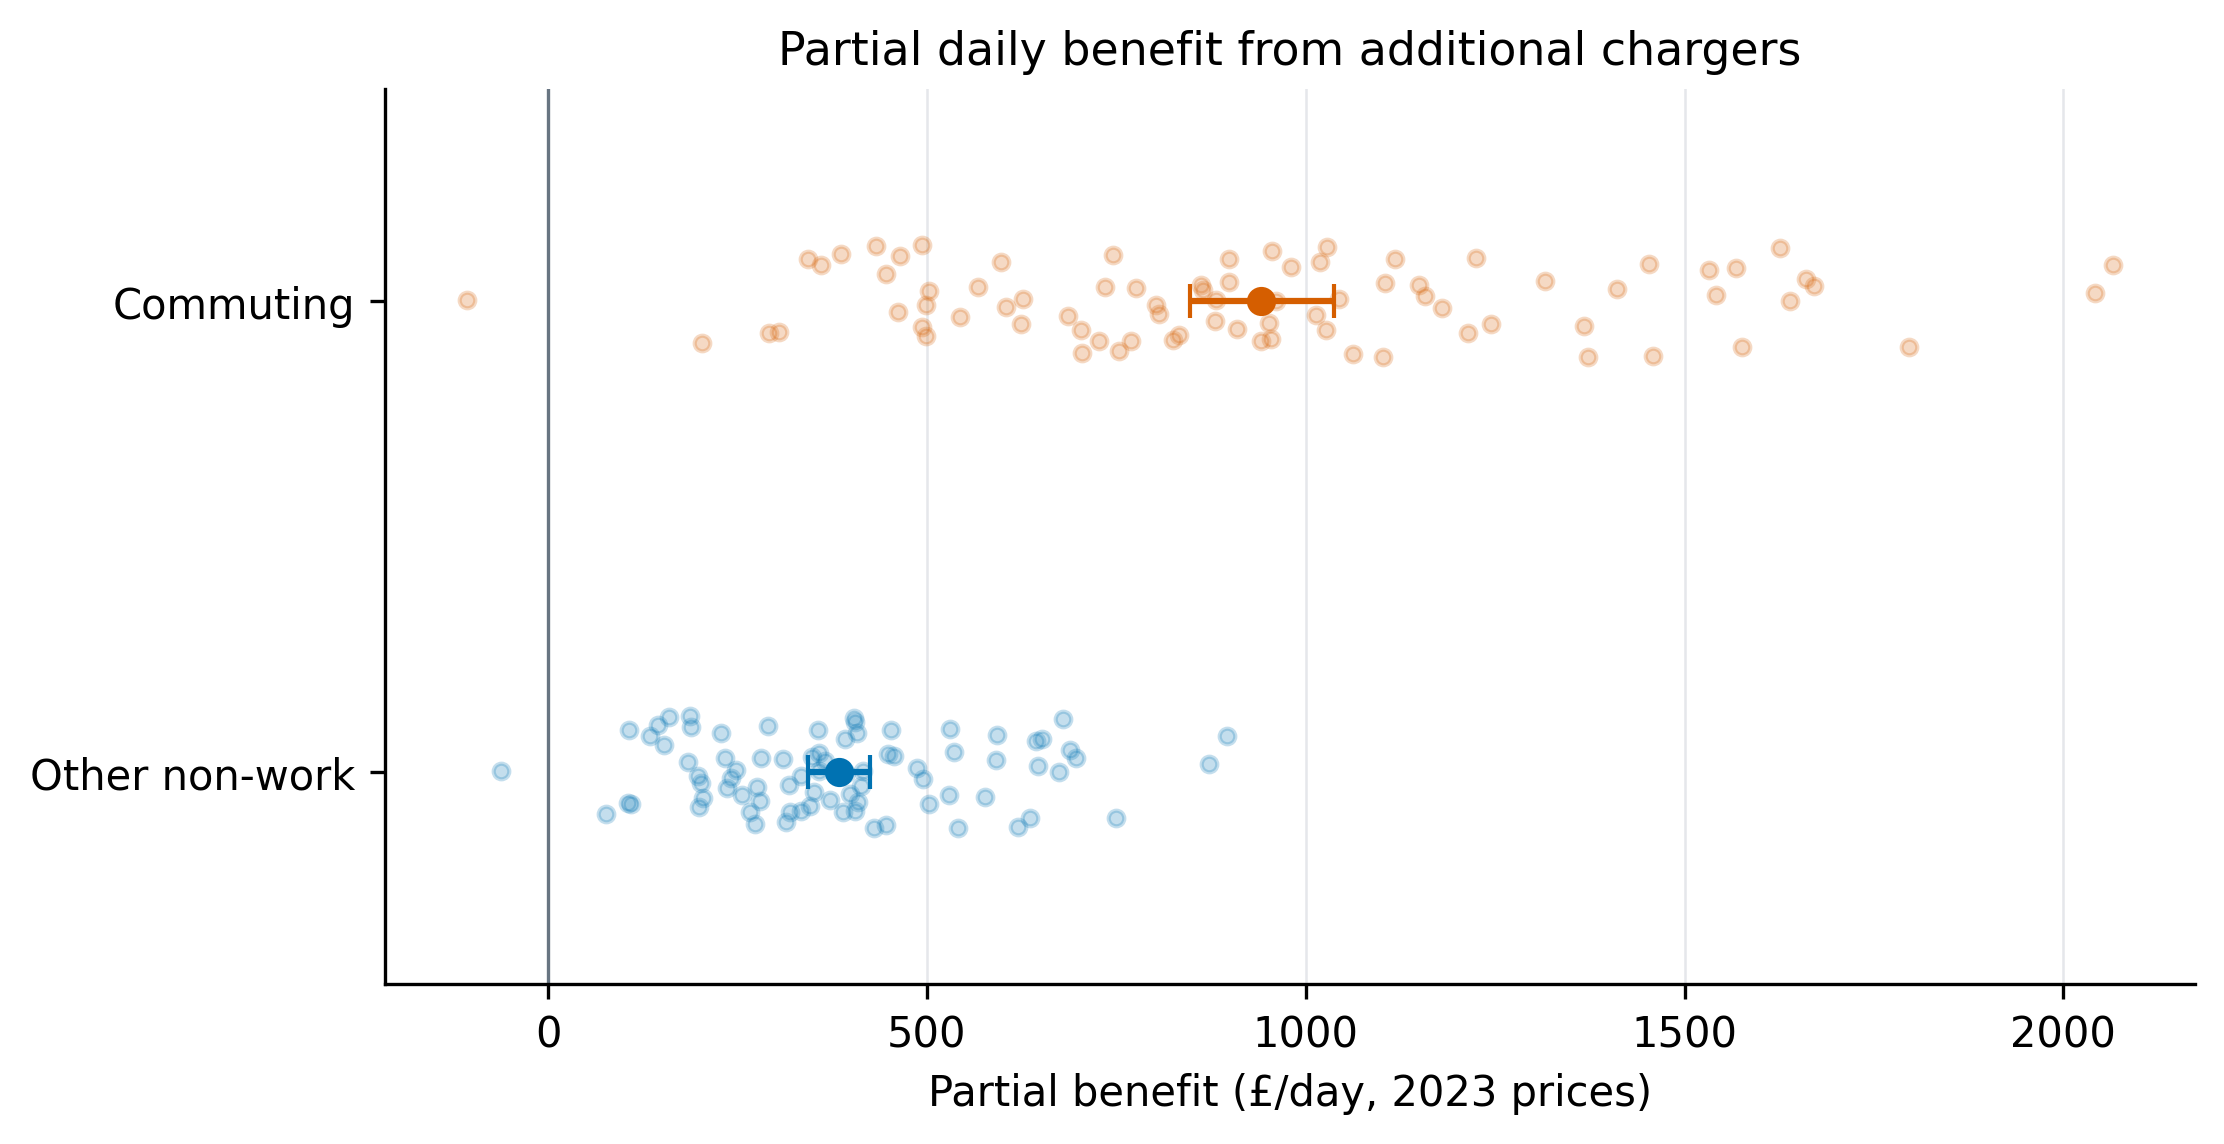

Separate journey-purpose scenarios using 2026 TAG time values in real 2023 market-price units, a waiting multiplier of 2, and central DESNZ energy resource costs. Light dots are individual paired-run results; dark markers and bars show the mean and its 95% paired bootstrap CI. Energy includes an accounting allowance to restore terminal battery energy. Unobserved journey outcomes, infrastructure, maintenance, fleet repositioning, degradation and externalities remain outside this partial benefit. It is not operator profit.

In [4]:
daily = pd.DataFrame(report['daily'])
display(daily[['purpose','component','mean','low','high']].round(2))
display(Image(filename=str(ROOT/'figures/02_daily_value.png'), width=900))
display(Markdown(captions['02_daily_value']))

## 5. Additional investment: a switching-value calculation

The annualised partial budget is
$$B^{\rm partial}=\sum_y d_y\,\overline{b_y^{\rm partial}}\,DF_y,$$
where $d_y$ is the declared number of repeated operating days and $DF_y$ the discount factor to 2023. Values of time and energy follow their saved official annual series. No demand growth is assumed.

For additional annual costs/liabilities $M$, the capital amount payable in 2026 that uses up this partial budget is
$$K^*(M)=\frac{B^{\rm partial}-M\sum_y DF_y}{DF_{2026}}.$$

This is a **frontier**, not an estimated charger price. At its zero-cost intercept, the entire budget remains available to cover capital **and every omitted cost or outcome**. In particular, unresolved journeys, fleet-position restoration, maintenance, battery wear, grid work, replacement and externalities must not be forgotten. Renewal and residual values need a separate allowance unless already incorporated as annual equivalents.

The HMT October 2026 schedule is used. The still-published May 2026 TAG schedule is tested separately. The example duration is not a declaration that chargers survive ten years.

Above: partial budget in 2023 GBP, discounted to 2023; not profit or a final investment valuation.


,purpose,mean,low,high
0,other_non_work,1021413.0,916960.0,1130229.0
1,commuting,2432666.0,2191587.0,2683011.0


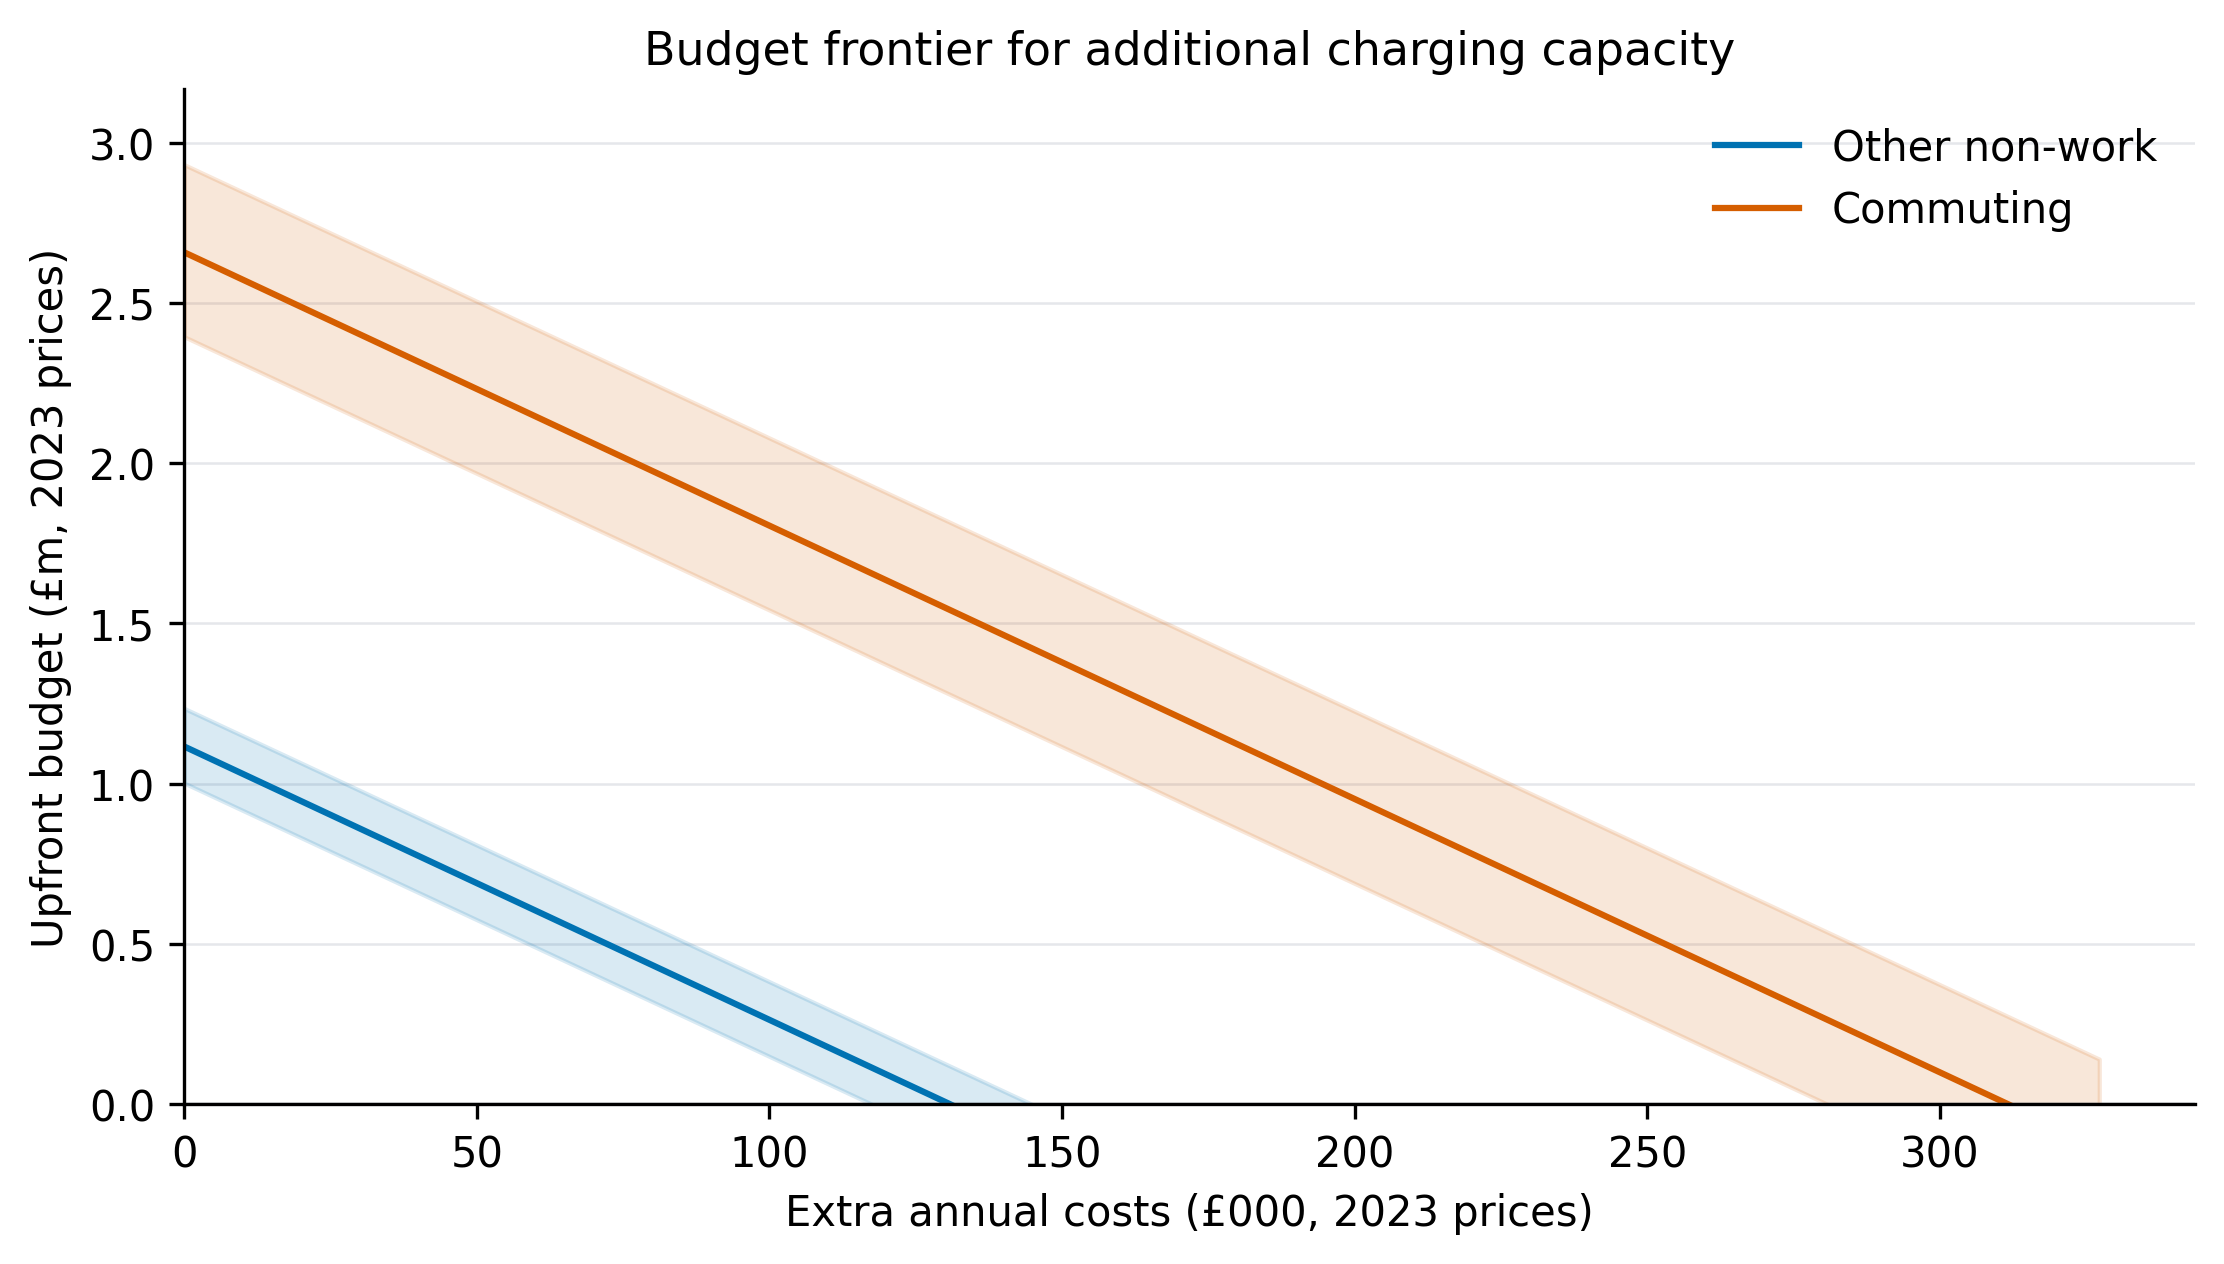

Conditional upfront budget for the compared package, with expenditure in 2026, 300 operating days per year and a 10-year scenario from 2027. Curves show the partial time-and-energy benefit remaining after an explicit additional annual cost/liability; shading is the 95% conditional bootstrap CI of the mean. These annual costs must cover omitted service outcomes and other recurring differences. Renewal/residual impacts require a separate allowance. Neither the horizontal intercept nor the vertical intercept is a charger price quote or a full investment recommendation.

In [5]:
display(pd.DataFrame(report['partial_budgets'])[['purpose','mean','low','high']].round(0))
print('Above: partial budget in 2023 GBP, discounted to 2023; not profit or a final investment valuation.')
display(Image(filename=str(ROOT/'figures/03_investment_frontier.png'), width=900))
display(Markdown(captions['03_investment_frontier']))

## 6. Annual use, duration and evidence sensitivity

The 5/10/15-year and 100/200/300/365-day cases explore the consequences of choices which are not yet calibrated. Annualisation assumes repetition of the finite-day experiment. Daily aircraft-position reset, deterioration and changes in demand are not modelled, so any resulting costs belong in the outstanding liability allowance.

TAG recommends ±60% for other non-work time values and ±25% for commuting. The saved DESNZ low/central/high energy series provide a separate source-based sensitivity. These scenarios have no assigned probabilities and are not pooled into the bootstrap CI.

,operating_days,years,mean,low,high
0,100,5,175293.0,157332.0,194009.0
1,100,10,340471.0,305653.0,376743.0
2,100,15,496081.0,445433.0,548805.0
3,200,5,350586.0,314663.0,388018.0
4,200,10,680942.0,611307.0,753486.0
5,200,15,992163.0,890865.0,1097610.0
6,300,5,525879.0,471995.0,582027.0
7,300,10,1021413.0,916960.0,1130229.0
8,300,15,1488244.0,1336298.0,1646415.0
9,365,5,639820.0,574260.0,708132.0


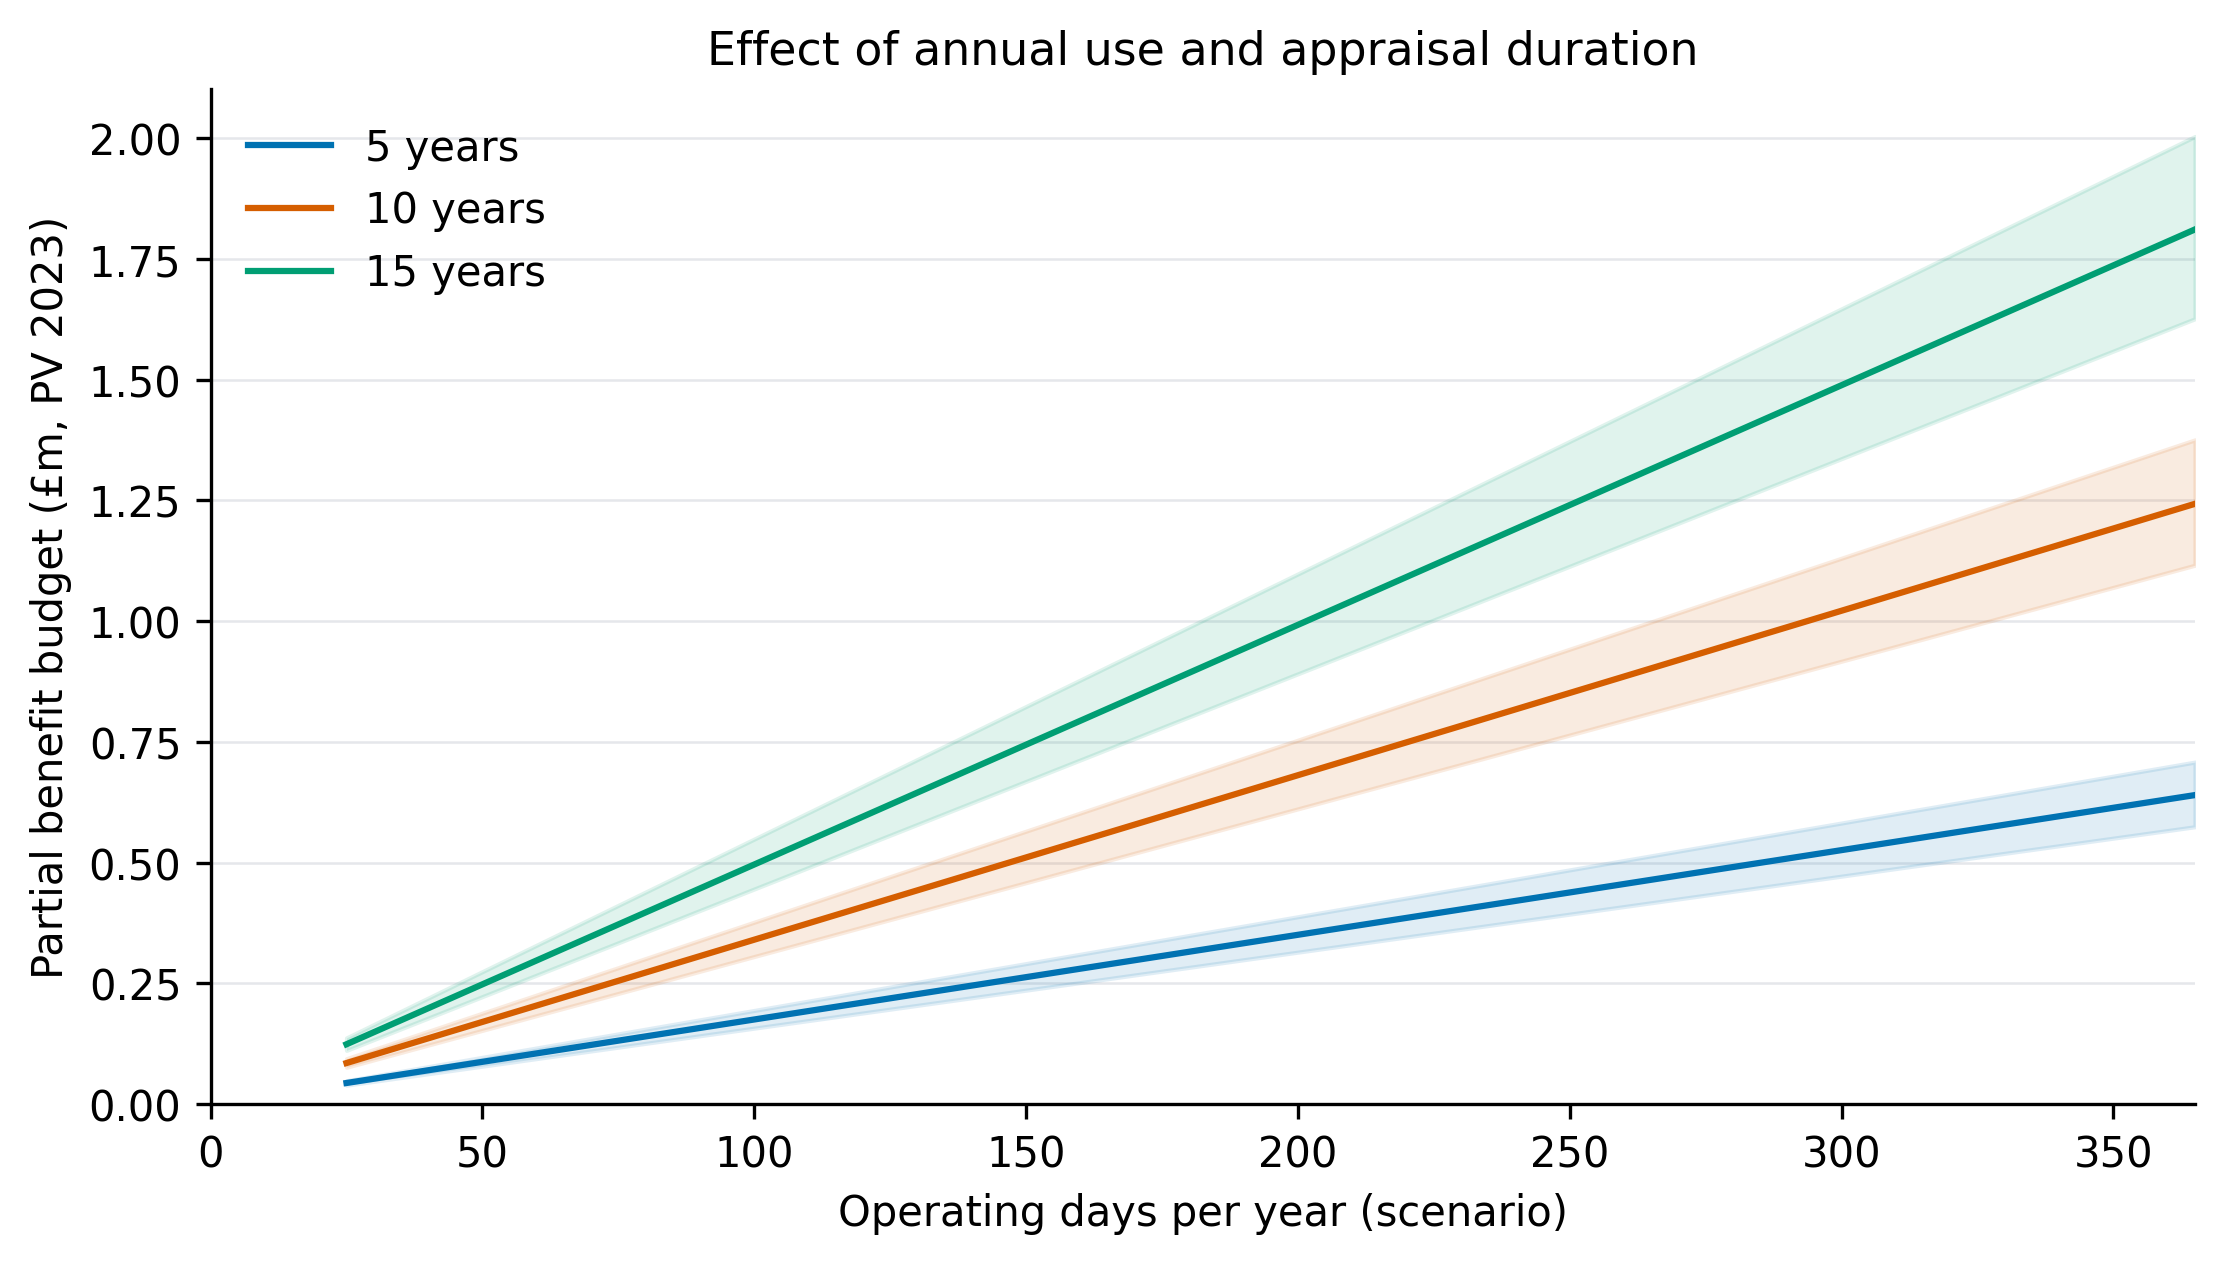

other non work valuation scenario with constant repeated daily demand and operation. Durations of 5, 10 and 15 years and annual days are illustrative scenarios, not measured aircraft/charger life or a demand forecast. Time and energy values vary by year using the official saved series; present values use 2023 prices and a 2023 PV base. Shading shows conditional 95% confidence intervals for simulation means. Unresolved residual journeys, fleet reset, future deterioration, replacement and other costs remain to be met from this partial budget.

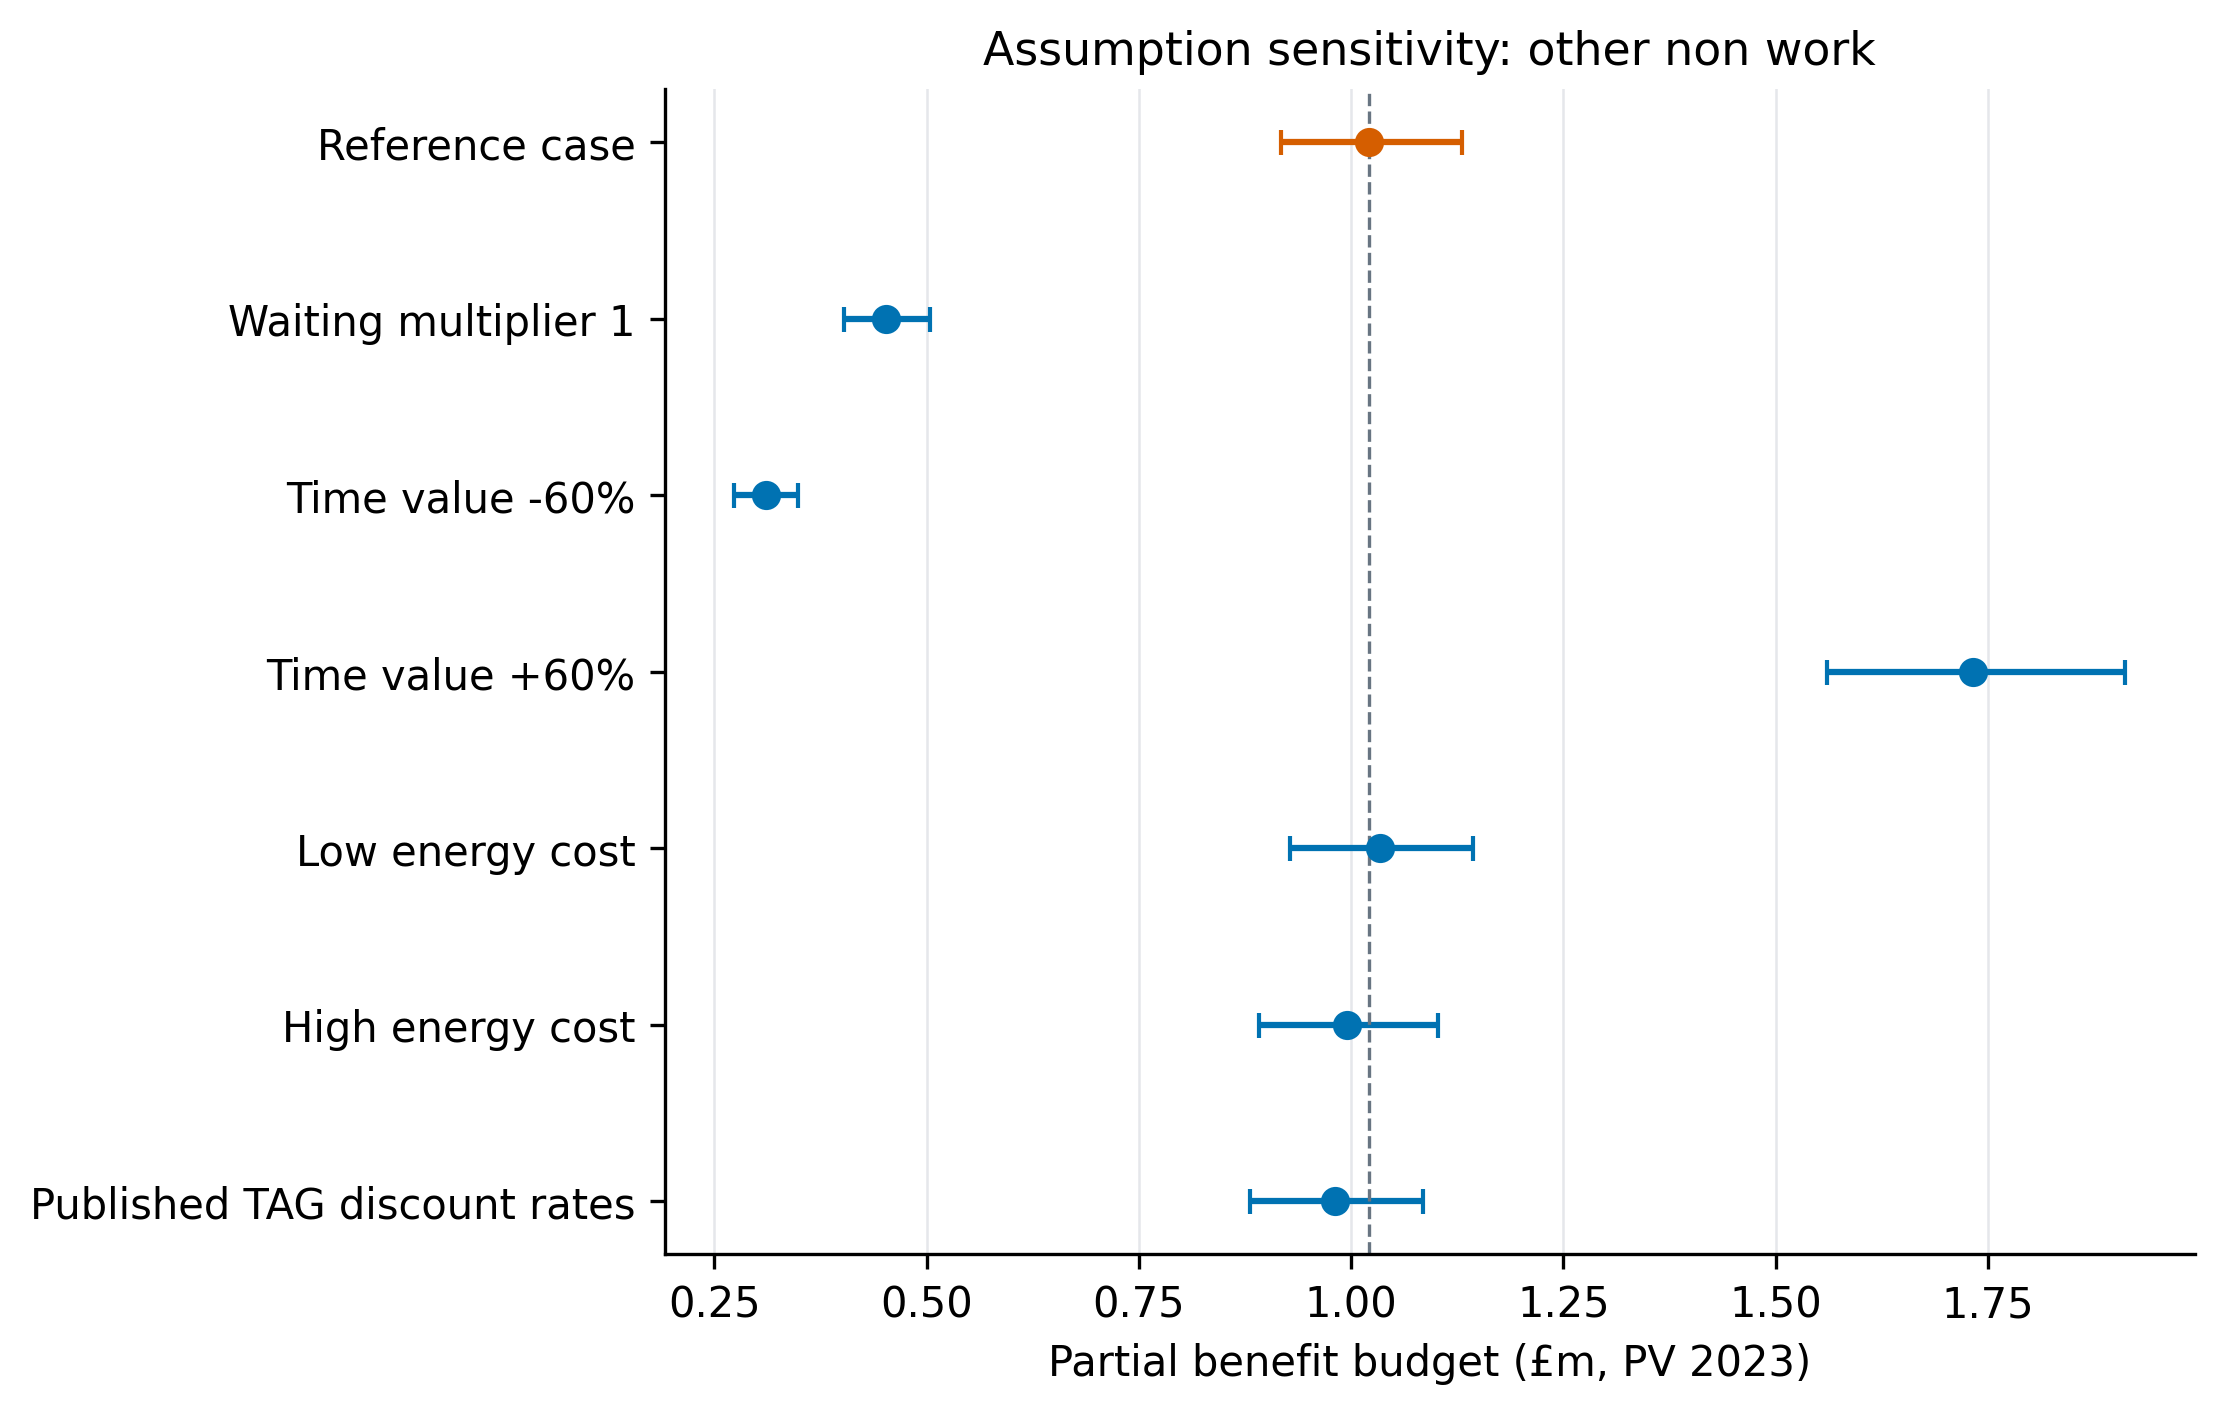

One-at-a-time valuation sensitivities around 300 operating days/year, 10 years from 2027, other non work travel, and the configured reference discount schedule. The value-of-time range is from TAG A1.3 (60% for other non-work, 25% for commuting). Waiting multiplier 1 tests transferring the public-transport multiplier of 2 to eVTOL. Energy scenarios come from DESNZ. The published TAG comparison uses the older May 2026 schedule. Bars are 95% conditional bootstrap CIs, not probabilities assigned to the alternative assumptions or a simultaneous confidence region.

,scenario,mean,low,high
0,Reference case,1021413.0,916960.0,1130229.0
1,Waiting multiplier 1,452466.0,403209.0,503694.0
2,Time value -60%,310405.0,273529.0,348337.0
3,Time value +60%,1732421.0,1560174.0,1912152.0
4,Low energy cost,1033975.0,928565.0,1143507.0
5,High energy cost,995242.0,892018.0,1102178.0
6,Published TAG discount rates,980777.0,880477.0,1085269.0


In [6]:
display(pd.DataFrame(report['annualisation'])[['operating_days','years','mean','low','high']].round(0))
display(Image(filename=str(ROOT/'figures/04_annualisation.png'), width=900))
display(Markdown(captions['04_annualisation']))
display(Image(filename=str(ROOT/'figures/05_sensitivity.png'), width=900))
display(Markdown(captions['05_sensitivity']))
display(pd.DataFrame(report['sensitivities'])[['scenario','mean','low','high']].round(0))

## 7. Unfinished journeys: the unresolved component remains visible

There are unfinished passengers in both configurations. Their observed waiting has already been counted, but their remaining travel, alternative-mode expenditure or lost-trip welfare has not been measured. More chargers alone do not establish better completion.

For an explicitly hypothetical common remaining generalised duration $r$ minutes per unfinished journey, the further time adjustment is
$$\Delta b_{i,y}^{\rm residual}=-\frac{v_y r}{60}(U_{i,B}-U_{i,A}).$$
Here $r$ is already generalised time, so it is not multiplied by the waiting multiplier again. This illustration assumes the same residual duration in both options and omits fares/lost-trip utility. It is not an estimate of real fallback travel. The zero row means this component is unvalued, not that later harm is known to be zero.

Separate diagnostics extended timetable slots after the original observation, without adding passengers. Some blocked trips still remained at 24 hours. This suggests a terminal dispatch/stand-management issue for subsequent simulator work. Those recovery records are not used to select a favourable subset or to generate the appraisal figures.

In [7]:
display(pd.DataFrame(report['residual_time_sensitivity'])[
    ['assumed_remaining_generalised_minutes','mean','low','high']].round(3))
print('Values above are additional GBP/day under the declared residual-time scenarios.')
diagnostics = json.loads((ROOT/'data/recovery_diagnostic.json').read_text())
display(pd.DataFrame(diagnostics).groupby('option').agg(
    diagnostic_runs=('seed','count'),
    runs_with_unfinished=('unfinished',lambda x: int((x>0).sum())),
    maximum_observation_min=('end_min','max')))

Values above are additional GBP/day under the declared residual-time scenarios.


,assumed_remaining_generalised_minutes,mean,low,high
0,0,0.000,0.000,0.000
1,60,-1.441,-4.324,1.532
2,120,-2.883,-8.649,3.063
3,240,-5.766,-17.297,6.126


,diagnostic_runs,runs_with_unfinished,maximum_observation_min
option,,,
one_charger,80,21,1440.0
two_chargers,80,40,1440.0


## 8. Result and limits

The experiment supports a measurable reduction in **observed waiting**, accompanied by extra flight energy. TAG valuations translate those quantities into a reproducible partial benefit calculation. They do not validate the synthetic demand, charging power or aircraft energy law.

Completion is a separate result: a run contains at least one unfinished journey in 21/80 baseline replications and 40/80 additional-charger replications. The paired interval above quantifies this difference. More charging capacity therefore does not establish a better overall service under the current scheduler; the unresolved service component matters to any final recommendation.

The analysis supplies a cost frontier and quantified sensitivity to time valuations, annual use, duration and discounting. A complete investment conclusion still needs the residual journey outcomes and the missing cost categories. A private operator's cash-flow analysis additionally requires fares and revenue: passengers' time savings are not airline cash receipts.

`net_present_value(...)` is provided for a later **explicit** cost scenario. It requires upfront cost, additional annual costs/liabilities, a renewal schedule and residual value; no missing cost is automatically replaced by zero. The published reference output remains the partial budget because the appropriate costs are not yet known.

**Outputs:** numeric tables are in `results/`; five figures are in `figures/` as PDF, SVG and PNG, with full captions. `python -m unittest test_appraisal -v` checks arithmetic, units, pairing, missing data and energy accounting.